# Praktikum Reinforcement Learning: Agent Penendang Bola ke Gawang

**Link video presentasi (YouTube, Unlisted):** https://youtu.be/KupdQqOlmYU

**Nama / NRP:** Muhammad Zaki Nanda Wahyudi / 5054251007

## 1. Pendahuluan

Pada project ini, sebuah agent (pemain sepak bola) belajar sendiri untuk **menggiring dan menendang bola ke gawang** di sebuah lapangan berbentuk grid. Tidak ada data berlabel. Agent hanya mencoba action, menerima reward, lalu memperbaiki strateginya.

**Pemetaan konsep RL ke project ini**

| Konsep | Di project ini |
|---|---|
| Agent | Pemain yang bergerak dan menendang |
| Environment | Lapangan grid 8x6 berisi bola dan gawang di sisi kanan |
| State | Posisi agent (x, y) dan posisi bola (x, y) |
| Action | atas, bawah, kiri, kanan, tendang |
| Reward | Dekat ke bola, bola mendekati gawang, gol, dan penalti |
| Policy | Aturan memilih action di setiap state (epsilon-greedy saat belajar, greedy saat evaluasi) |
| Value | Nilai Q(s, a) dan V(s) = max Q(s, a) |
| Proses belajar | Q-learning tabular dari interaksi berulang (episode) |
| Evaluasi | Reward per episode, success rate (persentase gol), dan perbandingan dengan agent acak |

**Versi environment:** bola **diam** dan hanya bergerak ketika ditendang. Agent harus berada di petak yang bersebelahan dengan bola, lalu menendang. Bola berpindah satu petak menjauhi agent. Karena itu agent harus belajar berputar ke sisi kiri bola supaya bola terdorong ke arah gawang.

## 2. Environment

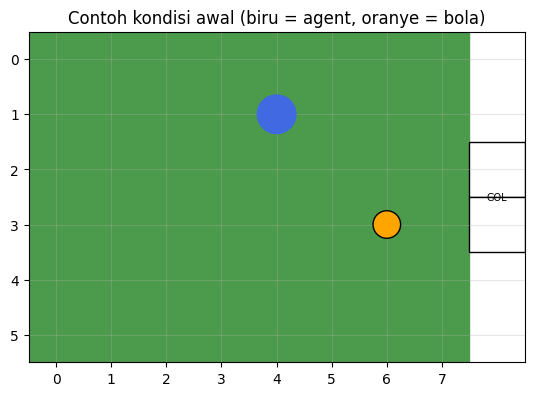

Jumlah state : 2304
Jumlah action: 5 ['atas', 'bawah', 'kiri', 'kanan', 'tendang']


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

class SoccerEnv:
    ACTIONS = ['atas', 'bawah', 'kiri', 'kanan', 'tendang']
    MOVES = {0: (0, -1), 1: (0, 1), 2: (-1, 0), 3: (1, 0)}

    def __init__(self, W=8, H=6, goal_rows=(2, 3), max_steps=60, shaping=True, seed=None, start_configs=None):
        self.W, self.H = W, H
        self.goal_rows = goal_rows      # baris gawang di sisi kanan lapangan
        self.max_steps = max_steps
        self.shaping = shaping          # True: pakai reward jarak, False: hanya reward gol
        self.rng = np.random.default_rng(seed)
        self.scored = False             # hanya untuk visualisasi: True bila bola masuk gawang
        self.start_configs = start_configs   # None = posisi awal acak bebas; atau daftar (ax, ay, bx, by)
        self.n_states = (W * H) ** 2
        self.n_actions = len(self.ACTIONS)

    # ---- bantuan ----
    def _state(self):
        (ax, ay), (bx, by) = self.agent, self.ball
        return ((ax * self.H + ay) * self.W + bx) * self.H + by

    def _d_agent_ball(self):
        return abs(self.agent[0] - self.ball[0]) + abs(self.agent[1] - self.ball[1])

    def _d_ball_goal(self):
        bx, by = self.ball
        return min(abs(bx - (self.W - 1)) + abs(by - gy) for gy in self.goal_rows)

    def _inside(self, x, y):
        return 0 <= x < self.W and 0 <= y < self.H

    # ---- API ala Gym ----
    def state_of(self, cfg):
        ax, ay, bx, by = cfg
        return ((ax * self.H + ay) * self.W + bx) * self.H + by

    def reset_to(self, cfg):                       # mulai dari konfigurasi (ax, ay, bx, by) tertentu
        ax, ay, bx, by = cfg
        self.agent, self.ball = (ax, ay), (bx, by)
        self.steps, self.scored = 0, False
        return self._state()

    def reset(self):
        if self.start_configs is not None:         # posisi awal diambil dari daftar konfigurasi yang diizinkan
            return self.reset_to(self.start_configs[int(self.rng.integers(len(self.start_configs)))])
        while True:
            self.ball = (int(self.rng.integers(1, self.W - 1)), int(self.rng.integers(1, self.H - 1)))
            self.agent = (int(self.rng.integers(0, self.W)), int(self.rng.integers(0, self.H)))
            if self.agent != self.ball:
                break
        self.steps = 0
        self.scored = False
        return self._state()

    def step(self, a):
        self.steps += 1
        reward, done, goal = -0.01, False, False       # penalti kecil per langkah
        d_ab_old, d_bg_old = self._d_agent_ball(), self._d_ball_goal()

        if a < 4:                                       # bergerak
            dx, dy = self.MOVES[a]
            nx, ny = self.agent[0] + dx, self.agent[1] + dy
            if self._inside(nx, ny) and (nx, ny) != self.ball:
                self.agent = (nx, ny)
            else:
                reward -= 0.05                          # menabrak dinding atau bola
        else:                                           # menendang
            ax, ay = self.agent
            bx, by = self.ball
            if abs(ax - bx) + abs(ay - by) == 1:        # bola bersebelahan dengan agent
                nbx, nby = bx + (bx - ax), by + (by - ay)
                if nbx == self.W and nby in self.goal_rows:
                    reward += 10.0                      # GOL
                    done = goal = True
                    self.scored = True                  # bola digambar di dalam gawang, state tidak diubah
                elif self._inside(nbx, nby):
                    self.ball = (nbx, nby)
                else:
                    reward -= 1.0                       # bola menabrak batas lapangan
            else:
                reward -= 0.2                           # menendang angin

        if self.shaping and not goal:
            reward += 0.1 * (d_ab_old - self._d_agent_ball())   # agent makin dekat ke bola
            reward += 0.5 * (d_bg_old - self._d_ball_goal())    # bola makin dekat ke gawang

        truncated = (not goal) and self.steps >= self.max_steps     # batas waktu, bukan akhir alami
        done = goal or truncated
        return self._state(), reward, done, {'goal': goal, 'terminated': goal, 'truncated': truncated}

    def render(self, ax=None, title=''):
        ax = ax or plt.gca()
        ax.set_xlim(-0.5, self.W + 0.5); ax.set_ylim(self.H - 0.5, -0.5); ax.set_aspect('equal')
        ax.add_patch(Rectangle((-0.5, -0.5), self.W, self.H, color='#4c9a4c', zorder=0))
        for gy in self.goal_rows:
            ax.add_patch(Rectangle((self.W - 0.5, gy - 0.5), 1, 1, color='white', ec='black', zorder=1))
        ax.text(self.W, np.mean(self.goal_rows), 'GOL', ha='center', va='center', fontsize=7)
        ball_pos = (self.W, self.ball[1]) if self.scored else self.ball      # bola masuk ke gawang saat gol
        ax.add_patch(Circle(ball_pos, 0.25, color='orange', ec='black', zorder=3))
        ax.add_patch(Circle(self.agent, 0.35, color='royalblue', zorder=2))
        ax.set_xticks(range(self.W)); ax.set_yticks(range(self.H)); ax.grid(alpha=0.3)
        ax.set_title(title)

env = SoccerEnv(seed=0)
env.reset()
env.render(title='Contoh kondisi awal (biru = agent, oranye = bola)')
plt.show()
print('Jumlah state :', env.n_states)
print('Jumlah action:', env.n_actions, env.ACTIONS)

### Desain reward

| Kejadian | Reward |
|---|---|
| Bola masuk gawang | +10 |
| Agent makin dekat ke bola (per petak) | +0,1 (sebaliknya -0,1) |
| Bola makin dekat ke gawang (per petak) | +0,5 (sebaliknya -0,5) |
| Setiap langkah | -0,01 |
| Menabrak dinding/bola | -0,05 |
| Menendang saat tidak dekat bola | -0,2 |
| Bola ditendang ke luar lapangan | -1 |

Reward jarak dibuat berbentuk **selisih jarak** (jarak lama dikurangi jarak baru). Dengan begitu agent tidak bisa mengumpulkan reward dengan bolak-balik di tempat: maju dapat +, mundur dapat - dengan besar sama.

## 3. Agent: Q-learning tabular

In [2]:
def epsilon_greedy(Q, s, eps, rng):
    if rng.random() < eps:
        return int(rng.integers(Q.shape[1]))
    best = np.flatnonzero(Q[s] == Q[s].max())
    return int(rng.choice(best))                 # tie-break acak

def train(shaping=True, episodes=20000, alpha=0.1, gamma=0.95,
          eps_start=1.0, eps_end=0.05, eps_decay_frac=0.6, seed=42,
          snapshots=None, checkpoints=(), start_configs=None, visited=None):
    env = SoccerEnv(shaping=shaping, seed=seed, start_configs=start_configs)
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.n_states, env.n_actions))
    rewards, goals = [], []
    for ep in range(episodes):
        if snapshots is not None and ep in checkpoints:
            snapshots[ep] = Q.copy()                 # simpan Q-table di tahap tertentu untuk simulasi
        eps = max(eps_end, eps_start - (eps_start - eps_end) * ep / (episodes * eps_decay_frac))
        s, done, total, goal = env.reset(), False, 0.0, False
        if visited is not None:
            visited[s] = True                        # catat state yang pernah dikunjungi saat training
        while not done:
            a = epsilon_greedy(Q, s, eps, rng)
            s2, r, done, info = env.step(a)
            if visited is not None:
                visited[s2] = True
            # terminated (gol): tidak ada nilai masa depan. truncated (kehabisan langkah): tetap bootstrap,
            # karena state tidak memuat sisa waktu sehingga timeout bukan akhir alami dari permainan.
            target = r if info['terminated'] else r + gamma * Q[s2].max()
            Q[s, a] += alpha * (target - Q[s, a])
            s, total, goal = s2, total + r, goal or info['goal']
        rewards.append(total); goals.append(goal)
    return Q, np.array(rewards), np.array(goals)

def evaluate(Q, episodes=500, seed=123, shaping=True, random_policy=False):
    env = SoccerEnv(shaping=shaping, seed=seed)
    rng = np.random.default_rng(seed)
    wins, steps_win, rets = 0, [], []
    for _ in range(episodes):
        s, done, total = env.reset(), False, 0.0
        while not done:
            a = int(rng.integers(env.n_actions)) if random_policy else int(np.argmax(Q[s]))
            s, r, done, info = env.step(a)
            total += r
        rets.append(total)
        if info['goal']:
            wins += 1; steps_win.append(env.steps)
    return wins / episodes, (np.mean(steps_win) if steps_win else float('nan')), np.mean(rets)

**Catatan terminal vs timeout.** Episode bisa berakhir karena dua hal yang diperlakukan berbeda:
- **Terminated:** bola masuk gawang. Tidak ada reward masa depan, jadi target Q = r.
- **Truncated:** langkah habis (`max_steps`). State tidak memuat sisa waktu, jadi timeout hanya pemotongan episode dan bukan akhir alami. Target tetap memakai bootstrap r + gamma * max Q(s').

## 4. Training

In [3]:
CHECKPOINTS = (1000, 2000)
snapshots = {}
Q, rewards, goals = train(shaping=True, snapshots=snapshots, checkpoints=CHECKPOINTS)
print('Training selesai.')
print('Success rate 1000 episode terakhir saat training:', goals[-1000:].mean())

Training selesai.
Success rate 1000 episode terakhir saat training: 0.998


## 5. Evaluasi

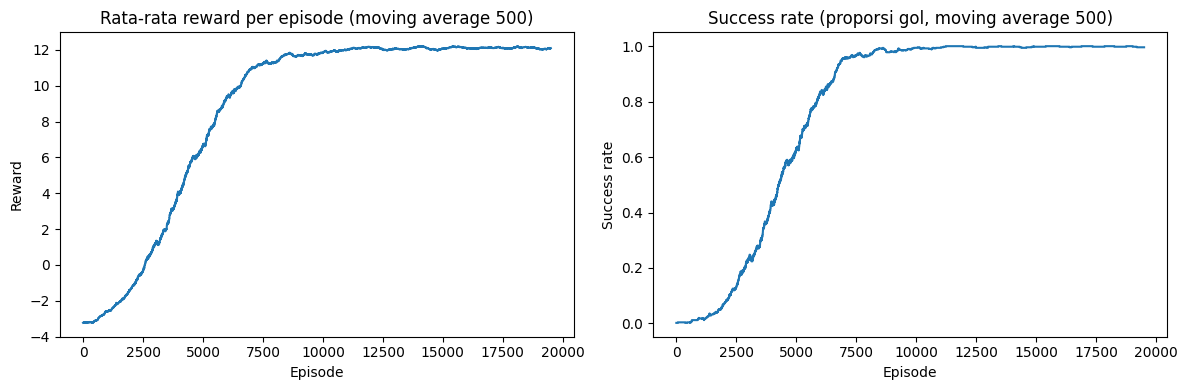

Agent hasil belajar : success rate = 100.0%, rata-rata langkah saat gol = 15.3, rata-rata reward = 12.24
Agent acak          : success rate = 0.4%, rata-rata reward = -3.22


In [4]:
def moving_avg(x, w=500):
    return np.convolve(x, np.ones(w) / w, mode='valid')

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(moving_avg(rewards)); axs[0].set_title('Rata-rata reward per episode (moving average 500)')
axs[0].set_xlabel('Episode'); axs[0].set_ylabel('Reward')
axs[1].plot(moving_avg(goals.astype(float))); axs[1].set_title('Success rate (proporsi gol, moving average 500)')
axs[1].set_xlabel('Episode'); axs[1].set_ylabel('Success rate')
plt.tight_layout(); plt.show()

sr_q, steps_q, ret_q = evaluate(Q)
sr_r, steps_r, ret_r = evaluate(Q, random_policy=True)
print(f'Agent hasil belajar : success rate = {sr_q:.1%}, rata-rata langkah saat gol = {steps_q:.1f}, rata-rata reward = {ret_q:.2f}')
print(f'Agent acak          : success rate = {sr_r:.1%}, rata-rata reward = {ret_r:.2f}')

### Satu episode dengan policy hasil belajar
Lintasan agent (garis biru) dan bola (garis oranye) pada satu episode greedy.

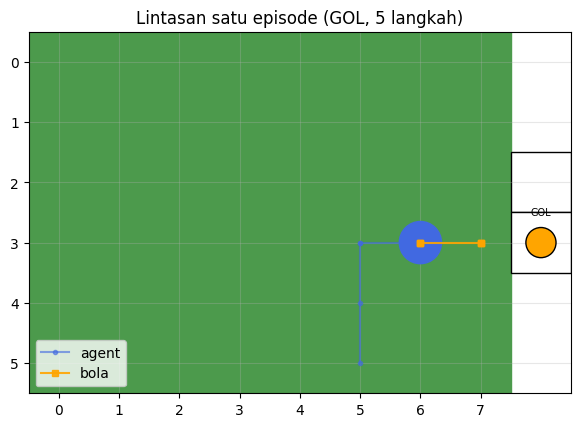

Urutan action: ['atas', 'atas', 'tendang', 'kanan', 'tendang']


In [5]:
def rollout(Q, seed=7):
    env = SoccerEnv(seed=seed)
    s, done = env.reset(), False
    first = (env.agent, env.ball)
    ag, bl, acts = [env.agent], [env.ball], []
    while not done:
        a = int(np.argmax(Q[s]))
        s, r, done, info = env.step(a)
        ag.append(env.agent); bl.append(env.ball); acts.append(env.ACTIONS[a])
    return env, ag, bl, acts, info['goal']

fig, ax = plt.subplots(figsize=(7, 5))
env_v, ag, bl, acts, goal = rollout(Q)
env_v.render(ax, title=f"Lintasan satu episode ({'GOL' if goal else 'gagal'}, {len(acts)} langkah)")
ax.plot(*zip(*ag), '-o', color='royalblue', alpha=0.6, ms=3, label='agent')
ax.plot(*zip(*bl), '-s', color='orange', alpha=0.9, ms=4, label='bola')
ax.legend(loc='lower left'); plt.show()
print('Urutan action:', acts)

### Visualisasi value V(s)
Untuk satu posisi bola tetap, peta di bawah memperlihatkan nilai V(s) = max Q(s, a) ketika agent berada di tiap petak. Nilai tinggi berarti dari petak itu agent diperkirakan bisa mencetak gol dengan reward besar.

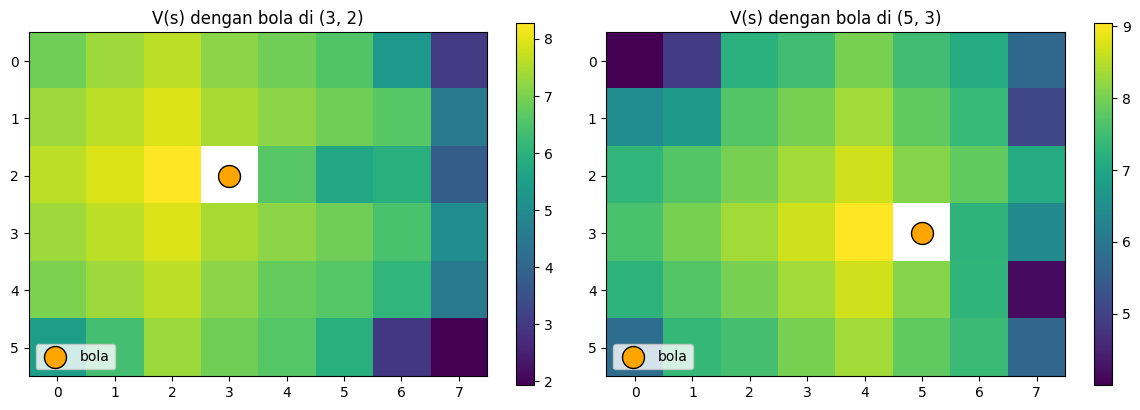

In [6]:
def value_map(Q, ball):
    env = SoccerEnv()
    V = np.full((env.H, env.W), np.nan)
    for ax_ in range(env.W):
        for ay_ in range(env.H):
            if (ax_, ay_) == ball:
                continue
            env.agent, env.ball = (ax_, ay_), ball
            V[ay_, ax_] = Q[env._state()].max()
    return V

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for ax, ball in zip(axs, [(3, 2), (5, 3)]):
    im = ax.imshow(value_map(Q, ball), cmap='viridis')
    ax.scatter(*ball, s=250, c='orange', edgecolors='black', label='bola')
    ax.set_title(f'V(s) dengan bola di {ball}'); ax.legend(loc='lower left')
    plt.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

## 5b. Simulasi: agent sebelum, selama, dan sesudah belajar
Empat agent dimulai dari **posisi awal yang sama**. Dari kiri ke kanan: agent acak (belum belajar), agent setelah 1.000 episode, setelah 2.000 episode, dan agent akhir. Animasi ini juga disimpan sebagai `simulasi_belajar.gif` untuk bahan video presentasi.

In [7]:
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import HTML
plt.rcParams['animation.embed_limit'] = 80

def collect_frames(choose_action, seed):
    env = SoccerEnv(seed=seed)
    s, done = env.reset(), False
    frames = [(env.agent, env.ball, 0, False)]
    while not done:
        s, r, done, info = env.step(choose_action(s))
        frames.append((env.agent, env.ball, env.steps, info['goal']))
    return frames

def make_animation(policies, seed, max_frames=40, fps=3):
    rng = np.random.default_rng(0)
    all_frames = [collect_frames(p(rng), seed) for _, p in policies]
    n = min(max(len(f) for f in all_frames), max_frames)
    fig, axs = plt.subplots(1, len(policies), figsize=(4.2 * len(policies), 3.6))
    view = SoccerEnv()
    def draw(i):
        for ax, (name, _), frames in zip(axs, policies, all_frames):
            ag, bl, t, goal = frames[min(i, len(frames) - 1)]
            ax.clear(); view.agent, view.ball, view.scored = ag, bl, goal
            view.render(ax, title=f"{name}\nlangkah {t}" + ("  GOL!" if goal else ""))
    anim = FuncAnimation(fig, draw, frames=n, interval=1000 / fps)
    plt.close(fig)
    return anim

greedy = lambda Qt: (lambda rng: (lambda s: int(np.argmax(Qt[s]))))
policies = [
    ('Acak (belum belajar)', lambda rng: (lambda s: int(rng.integers(5)))),
    (f'Episode {CHECKPOINTS[0]}', greedy(snapshots[CHECKPOINTS[0]])),
    (f'Episode {CHECKPOINTS[1]}', greedy(snapshots[CHECKPOINTS[1]])),
    ('Setelah training', greedy(Q)),
]
SIM_SEED = 3     # ganti angka ini untuk mencoba posisi awal lain
anim = make_animation(policies, SIM_SEED)
anim.save('simulasi_belajar.gif', writer=PillowWriter(fps=3))
HTML(anim.to_jshtml())

## 6. Eksperimen: apakah reward jarak membantu?
Dua konfigurasi dilatih dengan hiperparameter yang sama, masing-masing dengan 5 seed berbeda, supaya kesimpulan tidak bergantung pada satu kali training saja:
1. **Dengan reward jarak** (reward shaping).
2. **Hanya reward gol** (+10 saat gol, ditambah penalti langkah dan penalti kecil lainnya).

Metrik: episode pertama ketika *moving average* success rate (jendela 500 episode) mencapai 50%, 90%, dan 95%. Success rate di sini diukur **selama training**, yaitu dengan epsilon-greedy, sehingga ikut dipengaruhi jadwal epsilon yang sama untuk kedua konfigurasi.

In [8]:
SEEDS = [42, 1, 2, 3, 4]
CONFIGS = [('dengan reward jarak', True), ('hanya reward gol', False)]
runs = {}
for name, shaping in CONFIGS:
    runs[name] = {}
    for sd in SEEDS:
        Qs, rs, gs = train(shaping=shaping, seed=sd)
        runs[name][sd] = (Qs, gs)
print('Selesai melatih', len(CONFIGS) * len(SEEDS), 'agent.')

Selesai melatih 10 agent.


dengan reward jarak
  mencapai 50%: per seed [4751, 4917, 4853, 4717, 4774] | rata-rata 4802 ± 73 (tercapai di 5/5 seed)
  mencapai 90%: per seed [7110, 7029, 6946, 6800, 6949] | rata-rata 6967 ± 103 (tercapai di 5/5 seed)
  mencapai 95%: per seed [7391, 7936, 7482, 7570, 7851] | rata-rata 7646 ± 212 (tercapai di 5/5 seed)
  success rate evaluasi greedy per seed: ['100%', '100%', '100%', '100%', '100%']
hanya reward gol
  mencapai 50%: per seed [5353, 5077, 4920, 4975, 4989] | rata-rata 5063 ± 154 (tercapai di 5/5 seed)
  mencapai 90%: per seed [7159, 7074, 7186, 7027, 7083] | rata-rata 7106 ± 58 (tercapai di 5/5 seed)
  mencapai 95%: per seed [8098, 7654, 7835, 7453, 7756] | rata-rata 7759 ± 212 (tercapai di 5/5 seed)
  success rate evaluasi greedy per seed: ['100%', '100%', '100%', '100%', '100%']


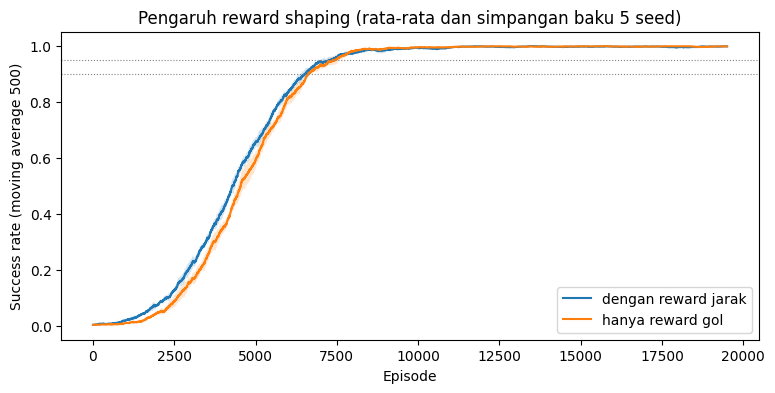

In [9]:
def episodes_to_reach(goals, level, w=500):
    m = moving_avg(goals.astype(float), w)
    hit = np.flatnonzero(m >= level)
    return int(hit[0]) + w if hit.size else None       # episode ke-berapa jendela pertama yang mencapai level

LEVELS = [0.5, 0.9, 0.95]
summary = {}
for name, shaping in CONFIGS:
    print(name)
    for lv in LEVELS:
        eps = [episodes_to_reach(runs[name][sd][1], lv) for sd in SEEDS]
        ok = [e for e in eps if e is not None]
        summary[(name, lv)] = ok
        txt = f'{np.mean(ok):.0f} ± {np.std(ok):.0f}' if ok else '-'
        print(f'  mencapai {lv:.0%}: per seed {eps} | rata-rata {txt} (tercapai di {len(ok)}/{len(SEEDS)} seed)')
    final = [evaluate(runs[name][sd][0], shaping=shaping)[0] for sd in SEEDS]
    print(f'  success rate evaluasi greedy per seed: {[f"{x:.0%}" for x in final]}')

plt.figure(figsize=(9, 4))
for name, _ in CONFIGS:
    curves = np.array([moving_avg(runs[name][sd][1].astype(float)) for sd in SEEDS])
    mu, sd_ = curves.mean(0), curves.std(0)
    plt.plot(mu, label=name); plt.fill_between(range(len(mu)), mu - sd_, mu + sd_, alpha=0.2)
for lv in LEVELS[1:]:
    plt.axhline(lv, color='gray', ls=':', lw=0.8)
plt.xlabel('Episode'); plt.ylabel('Success rate (moving average 500)')
plt.title('Pengaruh reward shaping (rata-rata dan simpangan baku 5 seed)'); plt.legend(); plt.show()

## 8. Analisis dan Kesimpulan

Seluruh angka di bawah berasal dari hasil eksperimen pada notebook ini. Hasil bisa sedikit berbeda jika notebook dijalankan ulang dengan seed lain.

### 8.1 Proses belajar agent
Pada awal training Q-table masih kosong dan epsilon masih tinggi, sehingga agent bergerak hampir acak. Reward rata-rata per episode berada di sekitar -3,2 dan success rate mendekati 0, mirip agent acak. Kenaikan mulai terlihat sekitar episode 1.500, lalu naik tajam sampai sekitar episode 7.500. Setelah itu kurva mendatar: reward sekitar 12 dan success rate mendekati 100%. Pada 1.000 episode terakhir, success rate saat training 99,8% (masih dengan epsilon-greedy).

Dengan reward jarak, rata-rata dari 5 seed, success rate mencapai 50% pada episode 4.802, 90% pada episode 6.967, dan 95% pada episode 7.646. Epsilon turun linear dari 1,0 ke 0,05 sampai episode 12.000. Jadi saat success rate sudah 95% (epsilon sekitar 0,39), agent masih sering mengeksplorasi dan policy-nya sudah efektif. Kenaikan kurva berasal dari dua hal yang berjalan bersamaan: nilai Q yang makin terisi lewat pengalaman, dan eksplorasi yang makin berkurang.

### 8.2 Perbandingan dengan agent acak
Saat evaluasi greedy, agent hasil belajar mencetak gol di 100% episode dengan rata-rata 15,3 langkah, dan reward rata-rata 12,24. Agent acak hanya berhasil 0,4% dengan reward rata-rata -3,22. Selisih ini menunjukkan bahwa perilaku agent memang hasil belajar dari reward, bukan kebetulan.

### 8.3 Policy dan value
Pada contoh episode, agent hanya memerlukan 5 langkah: `atas, atas, tendang, kanan, tendang`. Agent bergerak ke petak yang bersebelahan dengan bola, menendang, mengikuti bola, lalu menendang lagi sampai masuk gawang. Karena bola hanya bergerak saat ditendang dan menjauhi agent, agent harus berada di sisi bola yang berlawanan dengan arah gawang. Itu yang dipelajari policy-nya.

Peta V(s) mendukung hal itu. Untuk bola di (3, 2) dan di (5, 3), nilai tertinggi ada di petak tepat di sebelah kiri bola pada baris yang sama, yaitu posisi untuk mendorong bola ke arah gawang. Nilai turun ketika agent berada di sisi gawang dari bola, karena agent harus memutar dulu, dan paling rendah di sudut-sudut lapangan yang jauh dari bola. Jadi value berkaitan dengan jumlah langkah yang masih diperlukan untuk mencetak gol dari posisi tersebut.

### 8.4 Pengaruh reward shaping
Dua konfigurasi dilatih dengan hiperparameter sama pada 5 seed (rata-rata ± simpangan baku, dalam episode):

| Target success rate | Dengan reward jarak | Hanya reward gol |
|---|---|---|
| 50% | 4.802 ± 73 | 5.063 ± 154 |
| 90% | 6.967 ± 103 | 7.106 ± 58 |
| 95% | 7.646 ± 212 | 7.759 ± 212 |

Reward jarak cenderung mempercepat belajar, terutama di awal: pada 50% selisihnya sekitar 260 episode, lebih besar daripada simpangan antar seed. Pada 90% dan 95% selisihnya sekitar 140 dan 110 episode, sebanding dengan variasi antar seed, sehingga tidak bisa disimpulkan berbeda secara jelas dari 5 seed ini. Success rate evaluasi akhir sama, yaitu 100% pada semua seed di kedua konfigurasi.

Reward yang jarang (hanya saat gol) menyulitkan karena agent yang bergerak acak jarang menemukan gol (hanya 0,4% episode) sehingga hampir tidak ada sinyal untuk dipelajari. Reward jarak memberi sinyal bertahap: mendekati bola dan mendorong bola ke gawang sudah dihargai. Di grid sekecil ini (2.304 state), eksplorasi acak tetap cukup sering menemukan gol, sehingga agent tanpa reward jarak akhirnya juga berhasil dan selisihnya kecil. Dampak reward shaping kemungkinan lebih besar pada lapangan yang lebih besar atau episode yang lebih pendek.

### 8.5 Keterbatasan dan pengembangan
- Bola diam dan hanya bergerak saat ditendang; tidak ada bola yang meluncur.
- Lapangan kecil (8 x 6), tanpa kiper atau lawan, dan environment deterministik, sehingga 100% success rate relatif mudah dicapai.
- Hiperparameter (alpha, gamma, jadwal epsilon) tidak dituning dan hanya satu konfigurasi yang dicoba.
- Pengembangan: bola yang meluncur beberapa petak, kiper sebagai lawan, uji generalisasi yang lebih ketat (misalnya eksplorasi dibatasi atau lapangan lebih besar), dan mengganti Q-table dengan DQN.

### 8.6 Kesimpulan
1. Agent berhasil belajar sendiri lewat interaksi: dari perilaku acak (success rate 0,4%, reward -3,22) menjadi mencetak gol di 100% episode evaluasi dengan rata-rata 15,3 langkah.
2. Konsep RL muncul dan bisa dijelaskan dengan hasil eksperimen: agent (pemain), environment (grid dan gawang), state (posisi agent dan bola), action (5 aksi), reward (jarak ke bola, jarak bola ke gawang, gol), policy (greedy terhadap Q), dan value (peta V(s) tertinggi di belakang bola).
3. Reward jarak cenderung mempercepat belajar di awal, tetapi tidak mengubah hasil akhir pada lapangan sekecil ini.
